# Student Depression Prediction




## Project Overview

This project explores the use of machine learning to predict depression labels from student-related data. The objective is to develop and compare classification models while examining their performance on unseen test data.

The project follows a complete machine learning workflow, including data cleaning, exploratory data analysis (EDA), missing-value handling, categorical encoding, model training, and evaluation.

### Models Used
- Logistic Regression
- Decision Tree Classifier

### Evaluation Metrics
The models are compared using accuracy, precision, recall, F1-score, and confusion matrices.

**Note:** This project is intended for educational purposes and is not a clinical diagnostic tool.


## 2. Import Libraries

Import the Python libraries required for data manipulation, numerical operations, visualization, and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 3. Load Dataset

Load the Student Depression dataset into a pandas DataFrame for inspection and analysis.

In [2]:
student_dep_pred = pd.read_csv('Depression Student Dataset.csv')
student_dep_pred

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Female,34.0,4.0,2.0,More than 8 hours,Moderate,Yes,6.0,2.0,No,Yes
1,Male,21.0,2.0,3.0,5-6 hours,Unhealthy,Yes,6.0,5.0,Yes,Yes
2,Male,19.0,2.0,5.0,5-6 hours,Healthy,No,9.0,1.0,Yes,No
3,Female,22.0,1.0,2.0,7-8 hours,Unhealthy,No,1.0,2.0,No,No
4,Male,20.0,3.0,1.0,7-8 hours,Moderate,Yes,4.0,4.0,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...
527,Female,27.0,4.0,2.0,7-8 hours,Unhealthy,Yes,0.0,2.0,No,Yes
528,Female,25.0,2.0,2.0,More than 8 hours,Moderate,No,11.0,2.0,Yes,No
529,Male,28.0,5.0,4.0,More than 8 hours,Moderate,Yes,6.0,4.0,No,Yes
530,Female,32.0,NaN,1.0,7-8 hours,Moderate,Yes,7.0,3.0,Yes,Yes


## 4. Initial Data Inspection

Examine the dataset's dimensions, column names, data types, missing values, and descriptive statistics to understand its structure and identify potential data-quality issues.

In [3]:
# check missing values in each column
print("Missing values per column:")
print(student_dep_pred.isnull().sum())

# check the total number of missing values
print("\nTotal missing values:",
      student_dep_pred.isnull().sum().sum())

# check the number of duplicate rows
print("\nDuplicate rows:",
      student_dep_pred.duplicated().sum())

Missing values per column:
Gender                                   11
Age                                      20
Academic Pressure                        32
Study Satisfaction                       25
Sleep Duration                           15
Dietary Habits                           21
Have you ever had suicidal thoughts ?    16
Study Hours                              29
Financial Stress                         36
Family History of Mental Illness         17
Depression                                0
dtype: int64

Total missing values: 222

Duplicate rows: 30


In [4]:
# remove exact duplicate rows
student_dep_pred = student_dep_pred.drop_duplicates()

# verify the updated dataset
print("Dataset shape after removing duplicates:",
      student_dep_pred.shape)

print("Remaining duplicate rows:",
      student_dep_pred.duplicated().sum())

Dataset shape after removing duplicates: (502, 11)
Remaining duplicate rows: 0


In [5]:
# check missing values after removing duplicates
print("Missing values per column:")
print(student_dep_pred.isnull().sum())

print("\nTotal missing values:",
      student_dep_pred.isnull().sum().sum())

Missing values per column:
Gender                                   10
Age                                      20
Academic Pressure                        30
Study Satisfaction                       25
Sleep Duration                           15
Dietary Habits                           20
Have you ever had suicidal thoughts ?    15
Study Hours                              25
Financial Stress                         35
Family History of Mental Illness         15
Depression                                0
dtype: int64

Total missing values: 210


In [6]:
# inspect data types
print(student_dep_pred.dtypes)

Gender                                       str
Age                                      float64
Academic Pressure                        float64
Study Satisfaction                       float64
Sleep Duration                               str
Dietary Habits                               str
Have you ever had suicidal thoughts ?        str
Study Hours                              float64
Financial Stress                         float64
Family History of Mental Illness             str
Depression                                   str
dtype: object


Depression label counts:
Depression
Yes    252
No     250
Name: count, dtype: int64


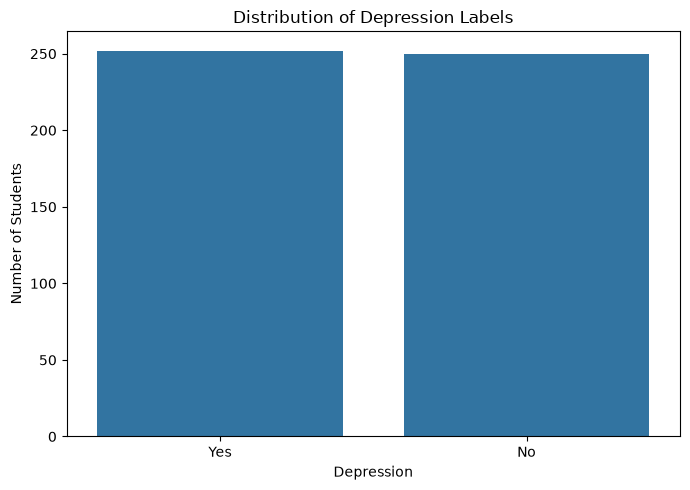

In [7]:
# check the distribution of depression labels
print("Depression label counts:")
print(student_dep_pred["Depression"].value_counts())

# visualize the target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=student_dep_pred, x="Depression")

plt.title("Distribution of Depression Labels")
plt.xlabel("Depression")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

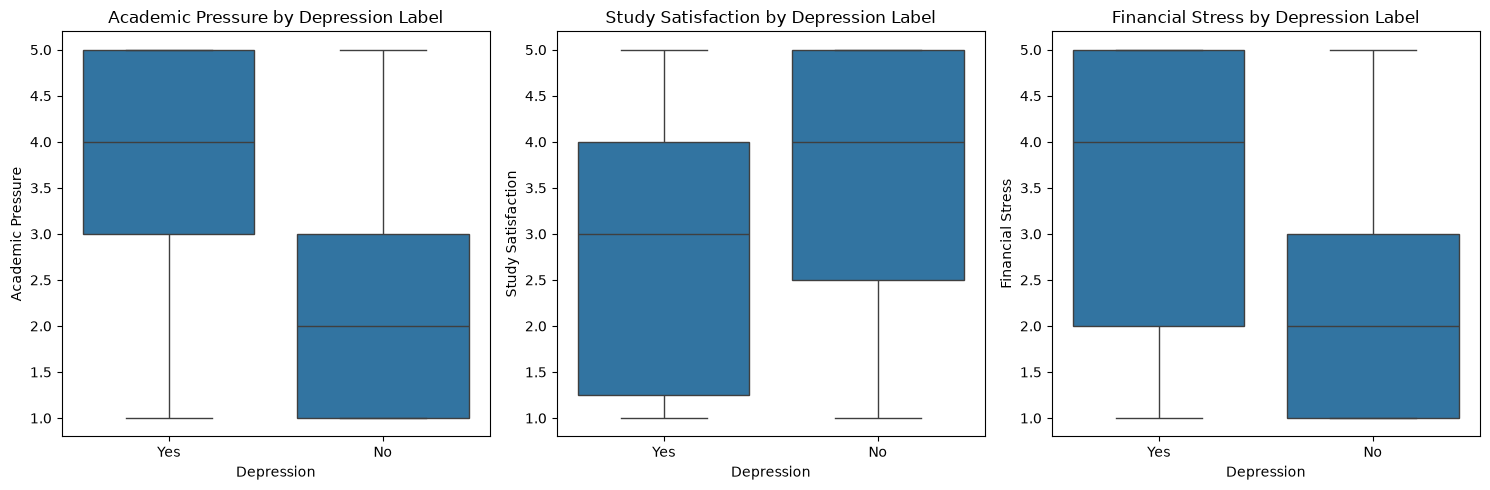

In [8]:
# compare numerical features across depression labels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

features = [
    "Academic Pressure",
    "Study Satisfaction",
    "Financial Stress"
]

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=student_dep_pred,
        x="Depression",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Depression Label")

plt.tight_layout()
plt.show()

In [9]:
# define numerical feature columns
numerical_cols = [
    'Age',
    'Academic Pressure',
    'Study Satisfaction',
    'Study Hours',
    'Financial Stress'
]

# define categorical feature columns
categorical_cols = [
    'Gender',
    'Sleep Duration',
    'Dietary Habits',
    'Have you ever had suicidal thoughts ?',
    'Family History of Mental Illness'
]

# define the target column
target_col = 'Depression'

print("Numerical features:", numerical_cols)
print("\nCategorical features:", categorical_cols)
print("\nTarget:", target_col)

Numerical features: ['Age', 'Academic Pressure', 'Study Satisfaction', 'Study Hours', 'Financial Stress']

Categorical features: ['Gender', 'Sleep Duration', 'Dietary Habits', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']

Target: Depression


In [10]:
# separate features and target
x = student_dep_pred.drop(columns=[target_col])
y = student_dep_pred[target_col]

# check their shapes
print("Features shape:", x.shape)
print("Target shape:", y.shape)

# preview the features
x.head()


Features shape: (502, 10)
Target shape: (502,)


,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness
0,Female,34.0,4.0,2.0,More than 8 hours,Moderate,Yes,6.0,2.0,No
1,Male,21.0,2.0,3.0,5-6 hours,Unhealthy,Yes,6.0,5.0,Yes
2,Male,19.0,2.0,5.0,5-6 hours,Healthy,No,9.0,1.0,Yes
3,Female,22.0,1.0,2.0,7-8 hours,Unhealthy,No,1.0,2.0,No
4,Male,20.0,3.0,1.0,7-8 hours,Moderate,Yes,4.0,4.0,Yes


In [11]:
from sklearn.model_selection import train_test_split

# split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# check the shapes
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (401, 10)
Testing features: (101, 10)
Training target: (401,)
Testing target: (101,)


In [12]:
from sklearn.impute import SimpleImputer

# create an imputer for numerical features
numerical_imputer = SimpleImputer(strategy="median")

# create an imputer for categorical features
categorical_imputer = SimpleImputer(strategy="most_frequent")

print("Imputers created successfully!")

Imputers created successfully!


In [13]:
# learn the median from numerical training data
numerical_imputer.fit(x_train[numerical_cols])

# learn the most frequent values from categorical training data
categorical_imputer.fit(x_train[categorical_cols])

print("Imputers fitted successfully!")

Imputers fitted successfully!


In [14]:
# fill missing values in numerical features
x_train[numerical_cols] = numerical_imputer.transform(
    x_train[numerical_cols]
)

x_test[numerical_cols] = numerical_imputer.transform(
    x_test[numerical_cols]
)

# fill missing values in categorical features
x_train[categorical_cols] = categorical_imputer.transform(
    x_train[categorical_cols]
)

x_test[categorical_cols] = categorical_imputer.transform(
    x_test[categorical_cols]
)

print("Missing values filled successfully!")

Missing values filled successfully!


In [15]:
# check missing values in the training set
print("Missing values in training set:", x_train.isnull().sum().sum())

# check missing values in the testing set
print("Missing values in testing set:", x_test.isnull().sum().sum())

Missing values in training set: 0
Missing values in testing set: 0


In [16]:
from sklearn.preprocessing import OneHotEncoder

# Keep unknown test-set categories from causing transform errors.
categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# learn the categories from the training data
categorical_encoder.fit(x_train[categorical_cols])

print("Encoder fitted successfully!")

Encoder fitted successfully!


In [17]:
# encode categorical features in the training set
x_train_encoded = categorical_encoder.transform(
    x_train[categorical_cols]
)

# encode categorical features in the testing set
x_test_encoded = categorical_encoder.transform(
    x_test[categorical_cols]
)

print("Training encoded shape:", x_train_encoded.shape)
print("Testing encoded shape:", x_test_encoded.shape)

Training encoded shape: (401, 13)
Testing encoded shape: (101, 13)


In [18]:
import pandas as pd

# convert encoded arrays into dataframes
x_train_encoded_df = pd.DataFrame(
    x_train_encoded,
    columns=categorical_encoder.get_feature_names_out(categorical_cols),
    index=x_train.index
)

x_test_encoded_df = pd.DataFrame(
    x_test_encoded,
    columns=categorical_encoder.get_feature_names_out(categorical_cols),
    index=x_test.index
)

# combine numerical and encoded categorical features
x_train_final = pd.concat(
    [x_train[numerical_cols], x_train_encoded_df],
    axis=1
)

x_test_final = pd.concat(
    [x_test[numerical_cols], x_test_encoded_df],
    axis=1
)

# check the final shapes
print("Final training shape:", x_train_final.shape)
print("Final testing shape:", x_test_final.shape)

Final training shape: (401, 18)
Final testing shape: (101, 18)


In [19]:
print("Missing values in training features:",
      x_train_final.isnull().sum().sum())

print("Missing values in testing features:",
      x_test_final.isnull().sum().sum())

print("Missing values in training target:",
      y_train.isnull().sum())

print("Missing values in testing target:",
      y_test.isnull().sum())

Missing values in training features: 0
Missing values in testing features: 0
Missing values in training target: 0
Missing values in testing target: 0


In [20]:
from sklearn.linear_model import LogisticRegression

# create the model
model = LogisticRegression(max_iter=1000)

# train the model
model.fit(x_train_final, y_train)

print("Model training completed!")

Model training completed!


In [21]:
# make predictions on the testing data
y_pred = model.predict(x_test_final)

# compare actual and predicted results
print("First 10 actual results:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted results:")
print(y_pred[:10])

First 10 actual results:
['No', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'No', 'Yes', 'No', 'Yes']

First 10 predicted results:
['No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes']


In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 94.06 %


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.94      0.94      0.94        50
         Yes       0.94      0.94      0.94        51

    accuracy                           0.94       101
   macro avg       0.94      0.94      0.94       101
weighted avg       0.94      0.94      0.94       101



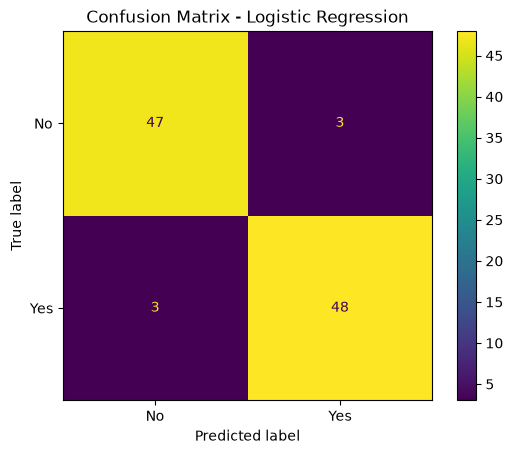

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

cm_display.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [25]:
from sklearn.metrics import accuracy_score

# accuracy on training data
y_train_pred = model.predict(x_train_final)
train_accuracy = accuracy_score(y_train, y_train_pred)

# accuracy on testing data
test_accuracy = accuracy_score(y_test, y_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Difference:", round((train_accuracy - test_accuracy) * 100, 2), "%")

Training Accuracy: 94.76 %
Testing Accuracy: 94.06 %
Difference: 0.7 %


In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# create and train the decision tree
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(x_train_final, y_train)

# make predictions
tree_pred = tree_model.predict(x_test_final)

# evaluate accuracy
tree_accuracy = accuracy_score(y_test, tree_pred)

print("Logistic Regression Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Decision Tree Accuracy:",
      round(tree_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 94.06 %
Decision Tree Accuracy: 85.15 %


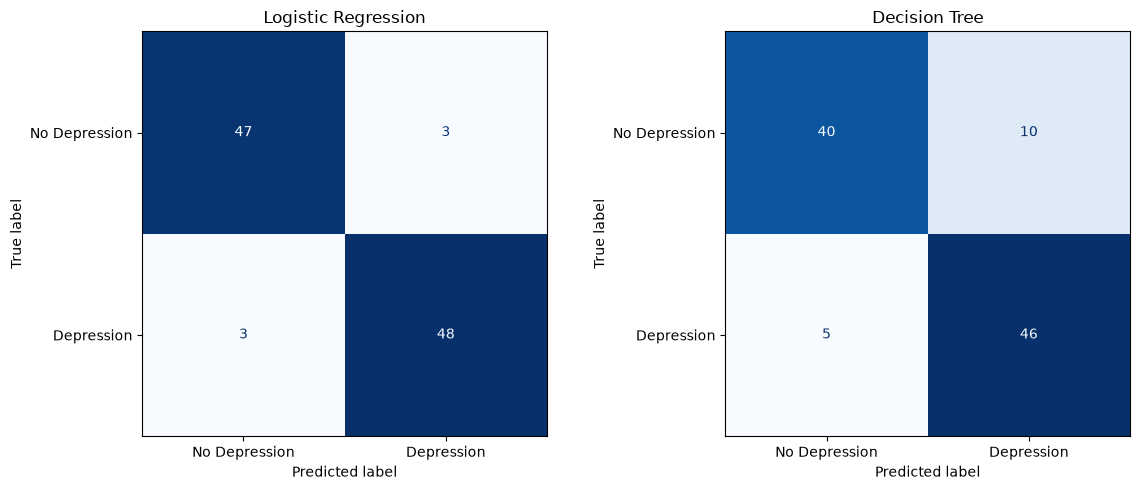

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in [
    (axes[0], "Logistic Regression", y_pred),
    (axes[1], "Decision Tree", tree_pred)
]:
    cm = confusion_matrix(
        y_test, predictions, labels=["No", "Yes"]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Depression", "Depression"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import classification_report

print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred))

print("=== Decision Tree ===")
print(classification_report(y_test, tree_pred))

=== Logistic Regression ===
              precision    recall  f1-score   support

          No       0.94      0.94      0.94        50
         Yes       0.94      0.94      0.94        51

    accuracy                           0.94       101
   macro avg       0.94      0.94      0.94       101
weighted avg       0.94      0.94      0.94       101

=== Decision Tree ===
              precision    recall  f1-score   support

          No       0.89      0.80      0.84        50
         Yes       0.82      0.90      0.86        51

    accuracy                           0.85       101
   macro avg       0.86      0.85      0.85       101
weighted avg       0.85      0.85      0.85       101



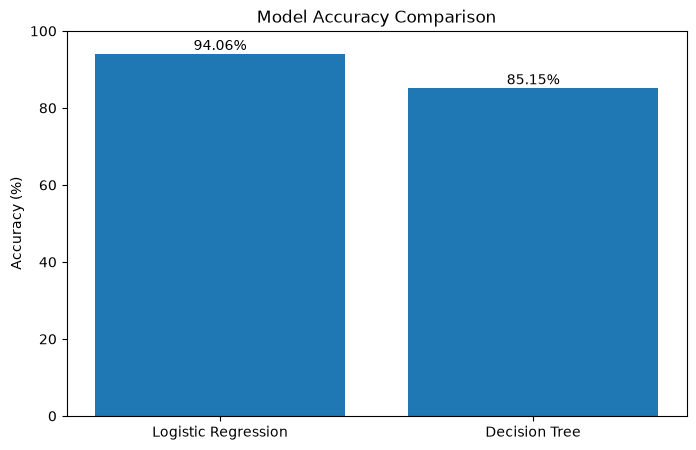

In [29]:
import matplotlib.pyplot as plt

models = ["Logistic Regression", "Decision Tree"]
accuracies = [
    accuracy_score(y_test, y_pred) * 100,
    accuracy_score(y_test, tree_pred) * 100
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

                                      Feature  Importance
15  Have you ever had suicidal thoughts ?_Yes    0.270368
1                           Academic Pressure    0.257504
2                          Study Satisfaction    0.132425
0                                         Age    0.120290
3                                 Study Hours    0.108790
4                            Financial Stress    0.061883
10           Sleep Duration_More than 8 hours    0.022451
13                   Dietary Habits_Unhealthy    0.022391
11                     Dietary Habits_Healthy    0.003900
5                               Gender_Female    0.000000


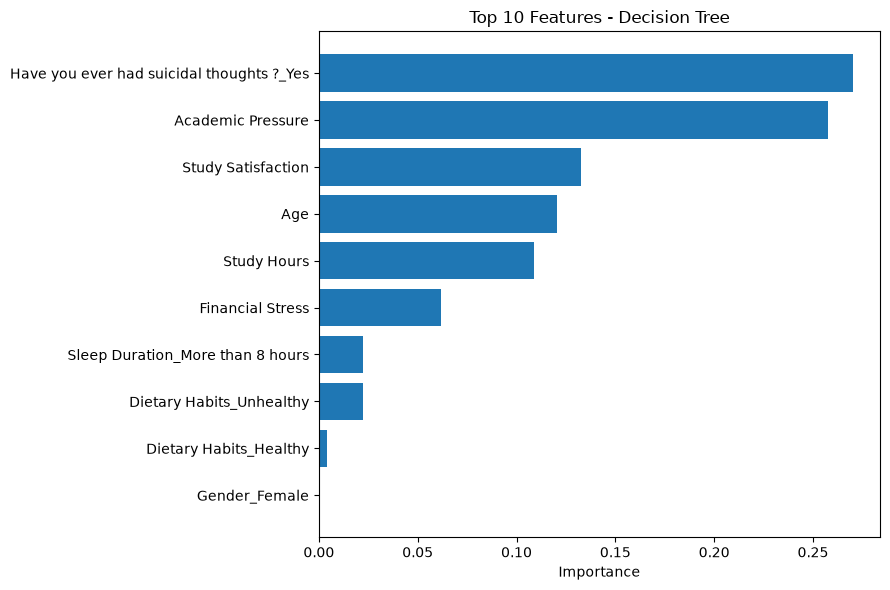

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": x_train_final.columns,
    "Importance": tree_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10))

# plot the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 10 Features - Decision Tree")
plt.tight_layout()
plt.show()

In [31]:
import joblib

joblib.dump(model, "logistic_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [32]:
import joblib

model_components = {
    "model": model,
    "numerical_imputer": numerical_imputer,
    "categorical_imputer": categorical_imputer,
    "categorical_encoder": categorical_encoder,
    "numerical_cols": numerical_cols,
    "categorical_cols": categorical_cols
}

joblib.dump(model_components, "student_depression_model.pkl")

print("Model and preprocessing tools saved successfully!")

Model and preprocessing tools saved successfully!


In [33]:
import joblib

# load the saved model components
loaded_components = joblib.load("student_depression_model.pkl")

# retrieve the model
loaded_model = loaded_components["model"]

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Saved model loaded successfully!
Model type: LogisticRegression


In [34]:
# predict using the loaded model
loaded_predictions = loaded_model.predict(x_test_final)

# compare with the original model's predictions
print("Original model predictions:", y_pred[:10])
print("Loaded model predictions:  ", loaded_predictions[:10])

# check whether all predictions match
print(
    "All predictions match:",
    (y_pred == loaded_predictions).all()
)

Original model predictions: ['No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes']
Loaded model predictions:   ['No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes']
All predictions match: True


In [35]:
# create one example student record
new_student = pd.DataFrame([{
    "Gender": "Female",
    "Age": 21,
    "Academic Pressure": 3,
    "Study Satisfaction": 2,
    "Sleep Duration": "Less than 5 hours",
    "Dietary Habits": "Unhealthy",
    "Have you ever had suicidal thoughts ?": "No",
    "Study Hours": 6,
    "Financial Stress": 3,
    "Family History of Mental Illness": "No"
}])

print(new_student)

   Gender  Age  Academic Pressure  Study Satisfaction     Sleep Duration  \
0  Female   21                  3                   2  Less than 5 hours   

  Dietary Habits Have you ever had suicidal thoughts ?  Study Hours  \
0      Unhealthy                                    No            6   

   Financial Stress Family History of Mental Illness  
0                 3                               No  


In [36]:
# retrieve preprocessing tools from the saved components
loaded_numerical_imputer = loaded_components["numerical_imputer"]
loaded_categorical_imputer = loaded_components["categorical_imputer"]
loaded_encoder = loaded_components["categorical_encoder"]

# fill missing numerical values, if any
new_student[numerical_cols] = loaded_numerical_imputer.transform(
    new_student[numerical_cols]
)

# fill missing categorical values, if any
new_student[categorical_cols] = loaded_categorical_imputer.transform(
    new_student[categorical_cols]
)

# encode categorical columns
new_student_encoded = loaded_encoder.transform(
    new_student[categorical_cols]
)

# convert encoded values into a dataframe
new_student_encoded_df = pd.DataFrame(
    new_student_encoded,
    columns=loaded_encoder.get_feature_names_out(categorical_cols),
    index=new_student.index
)

# combine numerical and encoded features
new_student_final = pd.concat(
    [new_student[numerical_cols], new_student_encoded_df],
    axis=1
)

print("Preprocessed student shape:", new_student_final.shape)
print(new_student_final)

Preprocessed student shape: (1, 18)
    Age  Academic Pressure  Study Satisfaction  Study Hours  Financial Stress  \
0  21.0                3.0                 2.0          6.0               3.0   

   Gender_Female  Gender_Male  Sleep Duration_5-6 hours  \
0            1.0          0.0                       0.0   

   Sleep Duration_7-8 hours  Sleep Duration_Less than 5 hours  \
0                       0.0                               1.0   

   Sleep Duration_More than 8 hours  Dietary Habits_Healthy  \
0                               0.0                     0.0   

   Dietary Habits_Moderate  Dietary Habits_Unhealthy  \
0                      0.0                       1.0   

   Have you ever had suicidal thoughts ?_No  \
0                                       1.0   

   Have you ever had suicidal thoughts ?_Yes  \
0                                        0.0   

   Family History of Mental Illness_No  Family History of Mental Illness_Yes  
0                                  1.0  

In [37]:
# predict using the loaded model
new_student_prediction = loaded_model.predict(new_student_final)

print("Model prediction:", new_student_prediction[0])

Model prediction: Yes


In [38]:
# get the model's estimated probabilities
prediction_probabilities = loaded_model.predict_proba(new_student_final)

# identify which probability belongs to each class
for class_name, probability in zip(
    loaded_model.classes_,
    prediction_probabilities[0]
):
    print(f"{class_name}: {probability * 100:.2f}%")

No: 11.49%
Yes: 88.51%


In [39]:
# get the predicted class
predicted_class = loaded_model.predict(new_student_final)[0]

# get the class with the highest probability
highest_probability_class = loaded_model.classes_[
    prediction_probabilities[0].argmax()
]

print("Predicted class:", predicted_class)
print("Highest probability class:", highest_probability_class)
print("Do they match?", predicted_class == highest_probability_class)

Predicted class: Yes
Highest probability class: Yes
Do they match? True


In [40]:
import pandas as pd
from IPython.display import display as show_table

# create sample data for three students
new_students = pd.DataFrame([
    {
        "Gender": "Female",
        "Age": 21,
        "Academic Pressure": 3,
        "Study Satisfaction": 2,
        "Sleep Duration": "Less than 5 hours",
        "Dietary Habits": "Unhealthy",
        "Have you ever had suicidal thoughts ?": "No",
        "Study Hours": 6,
        "Financial Stress": 3,
        "Family History of Mental Illness": "No"
    },
    {
        "Gender": "Male",
        "Age": 24,
        "Academic Pressure": 2,
        "Study Satisfaction": 4,
        "Sleep Duration": "7-8 hours",
        "Dietary Habits": "Healthy",
        "Have you ever had suicidal thoughts ?": "No",
        "Study Hours": 4,
        "Financial Stress": 2,
        "Family History of Mental Illness": "No"
    },
    {
        "Gender": "Female",
        "Age": 22,
        "Academic Pressure": 5,
        "Study Satisfaction": 1,
        "Sleep Duration": "Less than 5 hours",
        "Dietary Habits": "Unhealthy",
        "Have you ever had suicidal thoughts ?": "Yes",
        "Study Hours": 10,
        "Financial Stress": 5,
        "Family History of Mental Illness": "Yes"
    }
])

print("Input shape:", new_students.shape)
show_table(new_students)

Input shape: (3, 10)


,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness
0,Female,21,3,2,Less than 5 hours,Unhealthy,No,6,3,No
1,Male,24,2,4,7-8 hours,Healthy,No,4,2,No
2,Female,22,5,1,Less than 5 hours,Unhealthy,Yes,10,5,Yes


In [41]:
# preprocess all three students with the saved preprocessing components
batch_numerical_cols = loaded_components["numerical_cols"]
batch_categorical_cols = loaded_components["categorical_cols"]
batch_students_prepared = new_students.copy()

batch_students_prepared[batch_numerical_cols] = loaded_components[
    "numerical_imputer"
].transform(batch_students_prepared[batch_numerical_cols])

batch_students_prepared[batch_categorical_cols] = loaded_components[
    "categorical_imputer"
].transform(batch_students_prepared[batch_categorical_cols])

batch_encoded = loaded_components["categorical_encoder"].transform(
    batch_students_prepared[batch_categorical_cols]
)
batch_encoded_df = pd.DataFrame(
    batch_encoded,
    columns=loaded_components["categorical_encoder"].get_feature_names_out(
        batch_categorical_cols
    ),
    index=new_students.index
)
batch_students_final = pd.concat(
    [batch_students_prepared[batch_numerical_cols], batch_encoded_df],
    axis=1
)

# predict the class for each student
batch_predictions = loaded_model.predict(batch_students_final)

# calculate estimated probabilities
batch_probabilities = loaded_model.predict_proba(batch_students_final)

# display the results
for i, prediction in enumerate(batch_predictions):
    print(f"\nStudent {i + 1}")
    print(f"Predicted class: {prediction}")

    for class_name, probability in zip(
        loaded_model.classes_,
        batch_probabilities[i]
    ):
        print(f"{class_name}: {probability * 100:.2f}%")


Student 1
Predicted class: Yes
No: 11.49%
Yes: 88.51%

Student 2
Predicted class: No
No: 99.99%
Yes: 0.01%

Student 3
Predicted class: Yes
No: 0.00%
Yes: 100.00%


In [42]:
# check the preprocessed data
print("Original input shape:", new_students.shape)
print("Preprocessed shape:", batch_students_final.shape)

# check for missing values after preprocessing
print(
    "Missing values after preprocessing:",
    pd.DataFrame(batch_students_final).isnull().sum().sum()
)

Original input shape: (3, 10)
Preprocessed shape: (3, 18)
Missing values after preprocessing: 0


In [43]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display as show_table

# calculate metrics from actual test predictions
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Test Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, tree_pred) * 100
    ],
    "Precision (%)": [
        precision_score(y_test, y_pred, pos_label="Yes"),
        precision_score(y_test, tree_pred, pos_label="Yes")
    ],
    "Recall (%)": [
        recall_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, tree_pred, pos_label="Yes")
    ],
    "F1-score (%)": [
        f1_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, tree_pred, pos_label="Yes")
    ]
})

# convert all metrics to percentages
metric_columns = [
    "Precision (%)", "Recall (%)", "F1-score (%)"
]
model_comparison[metric_columns] *= 100

model_comparison.iloc[:, 1:] = (
    model_comparison.iloc[:, 1:].round(2)
)

show_table(model_comparison)


,Model,Test Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Logistic Regression,94.06,94.12,94.12,94.12
1,Decision Tree,85.15,82.14,90.20,85.98



## Conclusion

In this project, I developed and evaluated machine learning models to predict depression labels using student-related data. The workflow included data cleaning, exploratory data analysis, handling missing values, encoding categorical variables, and evaluating two classification algorithms.

### Key Findings

- **Logistic Regression** achieved a test accuracy of 94.06%.
- **Decision Tree** achieved a test accuracy of 85.15%.
- Logistic Regression performed better overall on the test set based on accuracy, precision, recall, and F1-score.
- The models were evaluated using classification metrics and confusion matrices to understand their prediction performance.

### Limitations and Future Improvements

- The model's performance is based on a single train-test split and may differ on new data.
- The dataset may not represent all student populations, so the results may not generalize to other settings.
- Future work could include cross-validation, hyperparameter tuning, and evaluation on an independent dataset.
- Further analysis could examine class-specific errors and the reliability of predicted probabilities.

**Important:** This project is an educational machine learning exercise. Its predictions should not be used to diagnose depression or replace assessment by a qualified mental health professional.
